# 0. Постановка задачи #

Необходимо откалибровать модель по наблюдаемым на рынке ценам таким образом, чтобы полученная модель была безарбитражной.

План проекта:
1) Необходимо получить достаточно большой объем данных по торгуемым на бирже опционам Call и Put
2) Построить кривую бескупонной доходности, чтобы моделировать коэффициенты дисконтирования $B(t, T)$, используемые в формуле Блека
3) Находим T-форвардную цену для каждого из опционов
4) Определяем тип опциона ATMF, ITMF, OTMF
5) Строим поверхность implied volatility

In [1]:
from dataclasses import dataclass
from datetime import datetime
from math import *
import numpy as np
import scipy.stats as st
from scipy.optimize import newton
import matplotlib.pyplot as plt
import pandas as pd

## 1. Получение данных по опционам ##
Были взяты опционы на SP500 с биржи CBOE за 12 месяцев. Дата получения данных: 04.11.2026 19:29 по МСК


In [2]:
import pandas as pd


def load_option_data(file_path):
    df = pd.read_csv(
        file_path,
        header=None,
        names=range(22),
        dtype=str,
        encoding='utf-8-sig'
    )

    df['quote_time'] = df[0].where(
        df[0].str.startswith('Date:', na=False)
    ).ffill()

    call_mask = df[1].str.fullmatch(
        r'SPXW?\d{6}C\d{8}', na=False
    )
    put_mask = df[12].str.fullmatch(
        r'SPXW?\d{6}P\d{8}', na=False
    )

    if (call_mask ^ put_mask).any():
        raise ValueError('Неполная строка опционных котировок')

    df = df.loc[call_mask & put_mask].copy()

    if df.empty:
        raise ValueError('Опционные контракты не найдены')

    columns = [
        'expiration', 'symbol', 'last', 'bid', 'ask',
        'volume', 'iv', 'delta', 'gamma',
        'open_interest', 'strike', 'quote_time'
    ]

    def parse(indices):
        options = df[indices + ['quote_time']].copy()
        options.columns = columns

        options['expiration'] = pd.to_datetime(
            options['expiration'].str.strip(),
            format='%a %b %d %Y'
        )

        numeric = [
            'last', 'bid', 'ask', 'volume', 'iv',
            'delta', 'gamma', 'open_interest', 'strike'
        ]

        options[numeric] = options[numeric].apply(
            pd.to_numeric, errors='raise'
        )

        symbol_date = pd.to_datetime(
            options['symbol'].str.extract(
                r'^(?:SPXW|SPX)(\d{6})[CP]',
                expand=False
            ),
            format='%y%m%d'
        )

        symbol_strike = (
            options['symbol'].str[-8:].astype(int) / 1000
        )

        if not (
            options['expiration'].eq(symbol_date).all()
            and options['strike'].eq(symbol_strike).all()
        ):
            raise ValueError('Несоответствие данных тикеру')

        if options['symbol'].duplicated().any():
            raise ValueError('Обнаружены дубликаты контрактов')

        options['mid'] = (options['bid'] + options['ask']) / 2

        options['class'] = options['symbol'].str.extract(
            r'^(SPXW|SPX)', expand=False
        )

        return options.sort_values(
            ['expiration', 'strike', 'class']
        ).reset_index(drop=True)

    calls = parse([0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11])
    puts = parse([0, 12, 13, 15, 16, 17, 18, 19, 20, 21, 11])

    return calls, puts

In [3]:
calls, puts = load_option_data('data/spx/options.csv')

In [4]:
calls = calls[calls['class'] == 'SPXW'].reset_index(drop=True)
calls

,expiration,symbol,last,bid,ask,volume,iv,delta,gamma,open_interest,strike,quote_time,mid,class
0,2026-11-04,SPXW261104C03200000,0.00,4479.8,4493.6,0,0.0000,1.0000,0.0000,0,3200.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,4486.70,SPXW
1,2026-11-04,SPXW261104C03400000,0.00,4280.0,4293.3,0,0.0000,1.0000,0.0000,0,3400.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,4286.65,SPXW
2,2026-11-04,SPXW261104C03600000,0.00,4079.6,4093.3,0,0.0000,1.0000,0.0000,0,3600.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,4086.45,SPXW
3,2026-11-04,SPXW261104C03800000,0.00,3879.2,3893.3,0,0.0000,1.0000,0.0000,0,3800.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,3886.25,SPXW
4,2026-11-04,SPXW261104C04000000,0.00,3679.8,3693.3,0,0.0000,1.0000,0.0000,0,4000.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,3686.55,SPXW
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9874,2027-09-30,SPXW270930C09490000,0.00,34.4,35.4,0,0.1290,0.0870,0.0002,0,9490.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,34.90,SPXW
9875,2027-09-30,SPXW270930C09495000,0.00,34.0,35.0,0,0.1290,0.0863,0.0002,0,9495.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,34.50,SPXW
9876,2027-09-30,SPXW270930C09500000,27.40,33.7,34.7,0,0.1289,0.0856,0.0002,102,9500.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,34.20,SPXW
9877,2027-09-30,SPXW270930C09600000,36.12,27.4,28.2,0,0.1284,0.0723,0.0001,25,9600.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,27.80,SPXW


In [5]:
puts = puts[puts['class'] == 'SPXW'].reset_index(drop=True)
puts

,expiration,symbol,last,bid,ask,volume,iv,delta,gamma,open_interest,strike,quote_time,mid,class
0,2026-11-04,SPXW261104P03200000,0.03,0.0,0.05,1,0.0000,0.0000,0.0000,309,3200.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,0.025,SPXW
1,2026-11-04,SPXW261104P03400000,0.05,0.0,0.05,2,0.0000,0.0000,0.0000,62,3400.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,0.025,SPXW
2,2026-11-04,SPXW261104P03600000,0.10,0.0,0.05,0,0.0000,0.0000,0.0000,91,3600.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,0.025,SPXW
3,2026-11-04,SPXW261104P03800000,0.50,0.0,0.05,0,8.1957,0.0000,0.0000,27,3800.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,0.025,SPXW
4,2026-11-04,SPXW261104P04000000,0.05,0.0,0.05,0,7.6215,0.0000,0.0000,30,4000.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,0.025,SPXW
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9874,2027-09-30,SPXW270930P09490000,0.00,1477.7,1516.30,0,0.1292,-0.9152,0.0002,0,9490.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,1497.000,SPXW
9875,2027-09-30,SPXW270930P09495000,0.00,1483.3,1522.80,0,0.1306,-0.9159,0.0002,0,9495.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,1503.050,SPXW
9876,2027-09-30,SPXW270930P09500000,0.00,1487.7,1527.20,0,0.1305,-0.9166,0.0002,0,9500.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,1507.450,SPXW
9877,2027-09-30,SPXW270930P09600000,0.00,1573.8,1613.00,0,0.1310,-0.9299,0.0001,0,9600.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,1593.400,SPXW


## 2. Коэффициент дисконтирования ##
Воспользуемся моделью Нельсона-Сигеля-Свенсона. Коэффициенты для модели возьмем с сайта Федерального резерва США

$$ y(t) = \beta_0 +
\beta_1 \cdot \frac{1 - e^{\frac{-t}{\tau_1}}}{\frac{t}{\tau_1}} +
\beta_2 \cdot \left (\frac{1 - e^{\frac{-t}{\tau_1}}}{\frac{t}{\tau_1}} - e^{\frac{-t}{\tau_1}} \right) +
\beta_3 \cdot \left (\frac{1 - e^{\frac{-t}{\tau_2}}}{\frac{t}{\tau_2}} - e^{\frac{-t}{\tau_2}} \right)
$$

Тогда цена бескупонной облигации с временем погашения $T$ и номиналом $X = 1$ в момент $t = 0$ будет $$ B(0, T) = e^{- \int_0^T r(u) du} = e^{-y(T) \cdot T}$$

Curve date: 2026-10-23 00:00:00


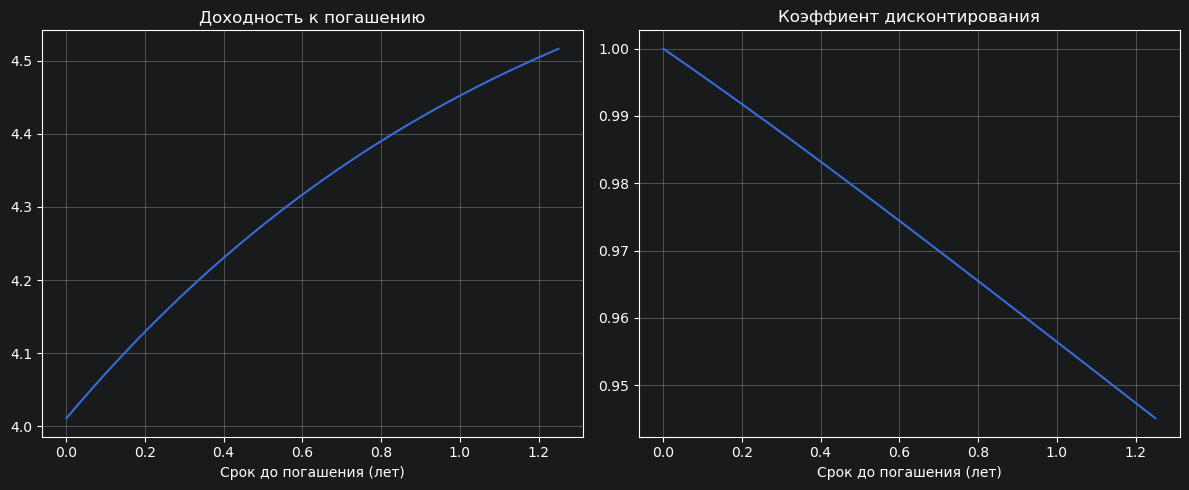

In [6]:
df = pd.read_csv('data/feds200628.csv', skiprows=9)

params = df[
    ['Date', 'BETA0', 'BETA1', 'BETA2',
     'BETA3', 'TAU1', 'TAU2']
].copy()

params['Date'] = pd.to_datetime(
    params['Date'], format='mixed', dayfirst=True
)

coefficients = ['BETA0', 'BETA1', 'BETA2',
                'BETA3', 'TAU1', 'TAU2']

valid = params[
    (params['Date'] <= '2026-11-04') &
    params[coefficients].notna().all(axis=1) &
    (params['TAU1'] > 0) &
    (params['TAU2'] > 0)
]

row = valid.sort_values('Date').iloc[-1]

print('Curve date:', row['Date'])


@dataclass
class NSS:
    beta0: float
    beta1: float
    beta2: float
    beta3: float
    tau1: float
    tau2: float

    def yield_to_maturity(self, t):
        x1 = t / self.tau1
        x2 = t / self.tau2

        a1 = -np.expm1(-x1) / x1
        a2 = -np.expm1(-x2) / x2

        return (
            self.beta0
            + self.beta1 * a1
            + self.beta2 * (a1 - np.exp(-x1))
            + self.beta3 * (a2 - np.exp(-x2))
        ) / 100

    def __call__(self, t):
        return self.yield_to_maturity(t)

    def discount_factor(self, t):
        return np.exp(-self(t) * t)


nss = NSS(*row[coefficients].astype(float).to_numpy())

T = np.linspace(0.001, 1.25, 1000)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(T, nss(T) * 100)
ax[0].set_title('Доходность к погашению')
ax[0].set_xlabel('Срок до погашения (лет)')
ax[0].grid(True)

ax[1].plot(T, nss.discount_factor(T))
ax[1].set_title('Коэффиент дисконтирования')
ax[1].set_xlabel('Срок до погашения (лет)')
ax[1].grid(True)

plt.tight_layout()
plt.show()

## 3. Подсчет форвардной цены ##

Используем только опционы имеющих экспирацию не ранее чем на день получения данных, так как иначе возможен случай $T = 0$, чего не допускает формула

Используем формулу:

$ F = \frac{(V^{call} - V^{put})}{B(0, T)} + K $, чтобы подобрать страйк $ K = F $ отбираем 5 наименьших разниц $V^{call} - V^{put} $ вычисляем по ним $F$, а затем выбираем из этих величин медиану


In [7]:
valuation_date = pd.Timestamp('2026-11-04')

calls = calls[calls['expiration'] > valuation_date].reset_index(drop=True)
puts = puts[puts['expiration'] > valuation_date].reset_index(drop=True)

expirations_df = (calls[['expiration']].drop_duplicates().sort_values('expiration').reset_index(drop=True))
expirations_df['T'] = (expirations_df['expiration'] - valuation_date).dt.days / 365
expirations_df['zero_rate'] = nss(expirations_df['T'].to_numpy())
expirations_df['discount_factor'] = np.exp(-expirations_df['zero_rate'] * expirations_df['T'])

In [8]:
def compute_forward_price(calls, puts, discount_factor):
    calls_prices = calls[(calls['bid'] > 0) & (calls['ask'] > 0)].set_index('strike')['mid']
    puts_prices = puts[(puts['bid'] > 0) & (puts['ask'] > 0)].set_index('strike')['mid']

    price_diff = (calls_prices - puts_prices).dropna()

    strikes = price_diff.abs().nsmallest(5).index

    forward_prices = strikes.to_numpy() + price_diff.loc[strikes].to_numpy() / discount_factor

    return np.median(forward_prices)

Для каждого из $T$ вычисляем соответствующую T-форвардную цену

In [9]:
for i, row in expirations_df.iterrows():
    expiration = row['expiration']
    discount_factor = row['discount_factor']

    calls_T = calls[calls['expiration'] == expiration]
    puts_T = puts[puts['expiration'] == expiration]

    expirations_df.loc[i, 'forward'] = compute_forward_price(
        calls_T,
        puts_T,
        discount_factor
    )

In [10]:
expirations_df[
    ['expiration', 'T', 'discount_factor', 'forward']
]

,expiration,T,discount_factor,forward
0,2026-11-05,0.002740,0.999890,7688.999340
1,2026-11-06,0.005479,0.999780,7691.049131
2,2026-11-09,0.013699,0.999450,7692.001101
3,2026-11-10,0.016438,0.999339,7693.255455
4,2026-11-11,0.019178,0.999229,7693.148572
5,2026-11-12,0.021918,0.999118,7693.548720
6,2026-11-13,0.024658,0.999008,7695.605562
7,2026-11-16,0.032877,0.998676,7695.387268
8,2026-11-17,0.035616,0.998565,7696.051509
9,2026-11-18,0.038356,0.998454,7696.402168


Соединим таблицы `expirations_df` вместе с `calls` и `puts`, чтобы в дальнейшем классифицировать наши опционы по типам $\ OTMF,\ ATMF,\ ITMF$

In [11]:
for i, row in expirations_df.iterrows():
    expiration = row['expiration']
    forward = row['forward']

    calls_T = calls[calls['expiration'] == expiration]
    puts_T = puts[puts['expiration'] == expiration]

    common_strikes = np.intersect1d(
        calls_T['strike'].unique(),
        puts_T['strike'].unique()
    )

    atmf_strike = common_strikes[
        np.argmin(np.abs(common_strikes - forward))
    ]

    expirations_df.loc[i, 'atmf_strike'] = atmf_strike

In [12]:
calls = calls.merge(
    expirations_df,
    on='expiration',
    how='left'
)

puts = puts.merge(
    expirations_df,
    on='expiration',
    how='left'
)

calls

,expiration,symbol,last,bid,ask,volume,iv,delta,gamma,open_interest,strike,quote_time,mid,class,T,zero_rate,discount_factor,forward,atmf_strike
0,2026-11-05,SPXW261105C03200000,4498.98,4481.1,4493.8,0,0.0000,1.0000,0.0000,1,3200.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,4487.45,SPXW,0.00274,0.040121,0.999890,7688.999340,7690.0
1,2026-11-05,SPXW261105C03400000,0.00,4281.1,4293.8,0,0.0000,1.0000,0.0000,0,3400.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,4287.45,SPXW,0.00274,0.040121,0.999890,7688.999340,7690.0
2,2026-11-05,SPXW261105C03600000,4099.15,4081.2,4093.8,0,0.0000,1.0000,0.0000,1,3600.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,4087.50,SPXW,0.00274,0.040121,0.999890,7688.999340,7690.0
3,2026-11-05,SPXW261105C03800000,0.00,3880.0,3894.6,0,0.0000,1.0000,0.0000,0,3800.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,3887.30,SPXW,0.00274,0.040121,0.999890,7688.999340,7690.0
4,2026-11-05,SPXW261105C04000000,0.00,3680.1,3694.2,0,0.0000,1.0000,0.0000,0,4000.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,3687.15,SPXW,0.00274,0.040121,0.999890,7688.999340,7690.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9611,2027-09-30,SPXW270930C09490000,0.00,34.4,35.4,0,0.1290,0.0870,0.0002,0,9490.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,34.90,SPXW,0.90411,0.044237,0.960795,7964.030195,7975.0
9612,2027-09-30,SPXW270930C09495000,0.00,34.0,35.0,0,0.1290,0.0863,0.0002,0,9495.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,34.50,SPXW,0.90411,0.044237,0.960795,7964.030195,7975.0
9613,2027-09-30,SPXW270930C09500000,27.40,33.7,34.7,0,0.1289,0.0856,0.0002,102,9500.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,34.20,SPXW,0.90411,0.044237,0.960795,7964.030195,7975.0
9614,2027-09-30,SPXW270930C09600000,36.12,27.4,28.2,0,0.1284,0.0723,0.0001,25,9600.0,Date: 4 ноября 2026 г. в 11:29 GMT-5,27.80,SPXW,0.90411,0.044237,0.960795,7964.030195,7975.0


In [13]:
calls['type'] = np.select([calls['strike'] == calls['atmf_strike'], calls['strike'] < calls['forward']], ['ATMF', 'ITMF'], default='OTMF')

puts['type'] = np.select([puts['strike'] == puts['atmf_strike'], puts['strike'] < puts['forward']], ['ATMF', 'OTMF'], default='ITMF')

puts_otmf = puts[puts['type'] == 'OTMF'].reset_index(drop=True)
calls_otmf = calls[calls['type'] == 'OTMF'].reset_index(drop=True)

Пользуемся методом секущих для нахождения корня уравнения $V^{market} = V^{call}(T, K, F, B, \sigma)$

Формула Блека:
$$ V_t^{call}(t, F_t) = B(t, T)(F_t \Phi(d1) - K\Phi(d_2))$$
$$ V_t^{put}(t, F_t) = B(t, T)(K \Phi(-d_2) - F_t \Phi(-d_1))$$
где $$ d_1 = \frac{1}{\sigma \sqrt{T - t}}\left(\ln \frac{F_t}{K} + \frac{\sigma^2}{2}(T - t)\right),\  d_2 = d_1 - \sigma \sqrt{T - t} $$

Для этого введем замены:
$$
y = \ln\!\left(\frac{F}{K}\right), \qquad
p = \frac{V}{B\sqrt{FK}}, \qquad
x = \hat{\sigma}\sqrt{T}, \qquad
\theta =
\begin{cases}
\phantom{-}1, & \text{для опциона колл} \\
-1, & \text{для опциона пут}
\end{cases}
$$

Тогда при данных обозначениях получаем формулу Блека в виде:
$$ \theta \left(e^{\frac{y}{2}}\Phi \left(\theta \left(\frac{y}{x} + \frac{x}{2}\right)\right) - e^{-\frac{y}{2}}\Phi \left(\theta \left(\frac{y}{x} - \frac{x}{2}\right)\right)\right) - p = 0$$ где условие на существование единственного положительного решения выглядит как:
$$ \theta \cdot \mathbf{1}(\theta y > 0) \cdot (e^{\frac{y}{2}} - e^{-\frac{y}{2}}) < p < e^{\theta \frac{y}{2}}$$

In [14]:
@np.vectorize
def implied_vol(forward_price, time_to_maturity, strike, option_price, call=True, discount_factor=1.0):
    x = log(forward_price/strike)
    p = option_price/(discount_factor*sqrt(forward_price*strike))

    if np.isclose(x, 0):
        return -2*st.norm.ppf((1-p)/2)/sqrt(time_to_maturity)

    theta = 1 if call else -1
    lower_bound = theta * (exp(x/2) - exp(-x/2)) if theta*x > 0 else 0.0
    upper_bound = exp(theta*x/2)
    if p <= lower_bound or p >= upper_bound:
        return nan

    sigma0 = sqrt(2*abs(x))

    def equation(sigma):
        return (theta*(exp(x/2)*st.norm.cdf(theta*(x/sigma+sigma/2)) -
                exp(-x/2)*st.norm.cdf(theta*(x/sigma-sigma/2))) - p)

    try:
        sigma = newton(equation, sigma0)
    except:
        return nan
    return sigma/sqrt(time_to_maturity)

Так же хотим исключить из данных неликвидные опционы, где величина спреда слишком большая, для этого назначим максимальную величину относительного спреда `max_spread = 0.3`

In [15]:
max_spread = 0.3

calls_used = calls[
    calls['type'].isin(['OTMF', 'ATMF']) &
    (calls['bid'] > 0) &
    (calls['ask'] >= calls['bid']) &
    ((calls['ask'] - calls['bid']) / calls['mid'] <= max_spread)
].copy().reset_index(drop=True)

puts_used = puts[
    puts['type'].isin(['OTMF', 'ATMF']) &
    (puts['bid'] > 0) &
    (puts['ask'] >= puts['bid']) &
    ((puts['ask'] - puts['bid']) / puts['mid'] <= max_spread)
].copy().reset_index(drop=True)

Вычислим implied volatility для оставшихся опционов

In [16]:
calls_used['impl_vol'] = implied_vol(
    calls_used['forward'].to_numpy(),
    calls_used['T'].to_numpy(),
    calls_used['strike'].to_numpy(),
    calls_used['mid'].to_numpy(),
    True,
    calls_used['discount_factor'].to_numpy()
)

puts_used['impl_vol'] = implied_vol(
    puts_used['forward'].to_numpy(),
    puts_used['T'].to_numpy(),
    puts_used['strike'].to_numpy(),
    puts_used['mid'].to_numpy(),
    False,
    puts_used['discount_factor'].to_numpy()
)

Соединим данные по OTMF опционам Call, ATMF опционам и OTMF опционам Put, получим поверхность подразумеваемой волатильности

In [17]:
calls_used['option_kind'] = 'Call'
puts_used['option_kind'] = 'Put'

surface = pd.concat([calls_used, puts_used], ignore_index=True)
surface = surface.dropna(subset=['impl_vol'])
surface = surface[(surface['impl_vol'] > 0) & np.isfinite(surface['impl_vol'])].copy()
surface = (surface.drop_duplicates(subset=['expiration', 'strike'], keep='first').sort_values(['expiration', 'strike']).reset_index(drop=True))

surface['log_moneyness'] = np.log(surface['strike'] / surface['forward'])
surface['total_variance'] = surface['impl_vol']**2 * surface['T']

In [18]:
surface

,expiration,symbol,last,bid,ask,volume,iv,delta,gamma,open_interest,...,T,zero_rate,discount_factor,forward,atmf_strike,type,impl_vol,option_kind,log_moneyness,total_variance
0,2026-11-05,SPXW261105P07010000,0.20,0.15,0.2,60,0.5752,-0.0024,0.0000,94,...,0.00274,0.040121,0.999890,7688.999340,7690.0,OTMF,0.627654,Put,-0.092453,0.001079
1,2026-11-05,SPXW261105P07020000,0.20,0.15,0.2,59,0.5671,-0.0025,0.0000,22,...,0.00274,0.040121,0.999890,7688.999340,7690.0,OTMF,0.618852,Put,-0.091027,0.001049
2,2026-11-05,SPXW261105P07025000,0.15,0.15,0.2,18,0.5630,-0.0026,0.0000,447,...,0.00274,0.040121,0.999890,7688.999340,7690.0,OTMF,0.614452,Put,-0.090315,0.001034
3,2026-11-05,SPXW261105P07030000,0.15,0.15,0.2,7,0.5590,-0.0026,0.0000,37,...,0.00274,0.040121,0.999890,7688.999340,7690.0,OTMF,0.610052,Put,-0.089604,0.001020
4,2026-11-05,SPXW261105P07040000,0.15,0.15,0.2,14,0.5509,-0.0027,0.0000,15,...,0.00274,0.040121,0.999890,7688.999340,7690.0,OTMF,0.601255,Put,-0.088182,0.000990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8582,2027-09-30,SPXW270930C09490000,0.00,34.40,35.4,0,0.1290,0.0870,0.0002,0,...,0.90411,0.044237,0.960795,7964.030195,7975.0,OTMF,0.128762,Call,0.175303,0.014990
8583,2027-09-30,SPXW270930C09495000,0.00,34.00,35.0,0,0.1290,0.0863,0.0002,0,...,0.90411,0.044237,0.960795,7964.030195,7975.0,OTMF,0.128695,Call,0.175830,0.014974
8584,2027-09-30,SPXW270930C09500000,27.40,33.70,34.7,0,0.1289,0.0856,0.0002,102,...,0.90411,0.044237,0.960795,7964.030195,7975.0,OTMF,0.128713,Call,0.176357,0.014979
8585,2027-09-30,SPXW270930C09600000,36.12,27.40,28.2,0,0.1284,0.0723,0.0001,25,...,0.90411,0.044237,0.960795,7964.030195,7975.0,OTMF,0.128189,Call,0.186828,0.014857


In [19]:
surface['expiration'].unique()

<DatetimeArray>
['2026-11-05 00:00:00', '2026-11-06 00:00:00', '2026-11-09 00:00:00',
 '2026-11-10 00:00:00', '2026-11-11 00:00:00', '2026-11-12 00:00:00',
 '2026-11-13 00:00:00', '2026-11-16 00:00:00', '2026-11-17 00:00:00',
 '2026-11-18 00:00:00', '2026-11-19 00:00:00', '2026-11-20 00:00:00',
 '2026-11-23 00:00:00', '2026-11-24 00:00:00', '2026-11-25 00:00:00',
 '2026-11-27 00:00:00', '2026-11-30 00:00:00', '2026-12-01 00:00:00',
 '2026-12-02 00:00:00', '2026-12-03 00:00:00', '2026-12-04 00:00:00',
 '2026-12-07 00:00:00', '2026-12-08 00:00:00', '2026-12-09 00:00:00',
 '2026-12-10 00:00:00', '2026-12-11 00:00:00', '2026-12-17 00:00:00',
 '2026-12-18 00:00:00', '2026-12-31 00:00:00', '2027-01-08 00:00:00',
 '2027-01-15 00:00:00', '2027-01-29 00:00:00', '2027-02-19 00:00:00',
 '2027-02-26 00:00:00', '2027-03-19 00:00:00', '2027-03-31 00:00:00',
 '2027-04-30 00:00:00', '2027-06-30 00:00:00', '2027-09-30 00:00:00']
Length: 39, dtype: datetime64[ns]

Оценим - насколько хорошо мы попадаем в impl_vol, которую предоставляет CBOE. Изобразим это на графике для 5ти произвольно взятых экспираций

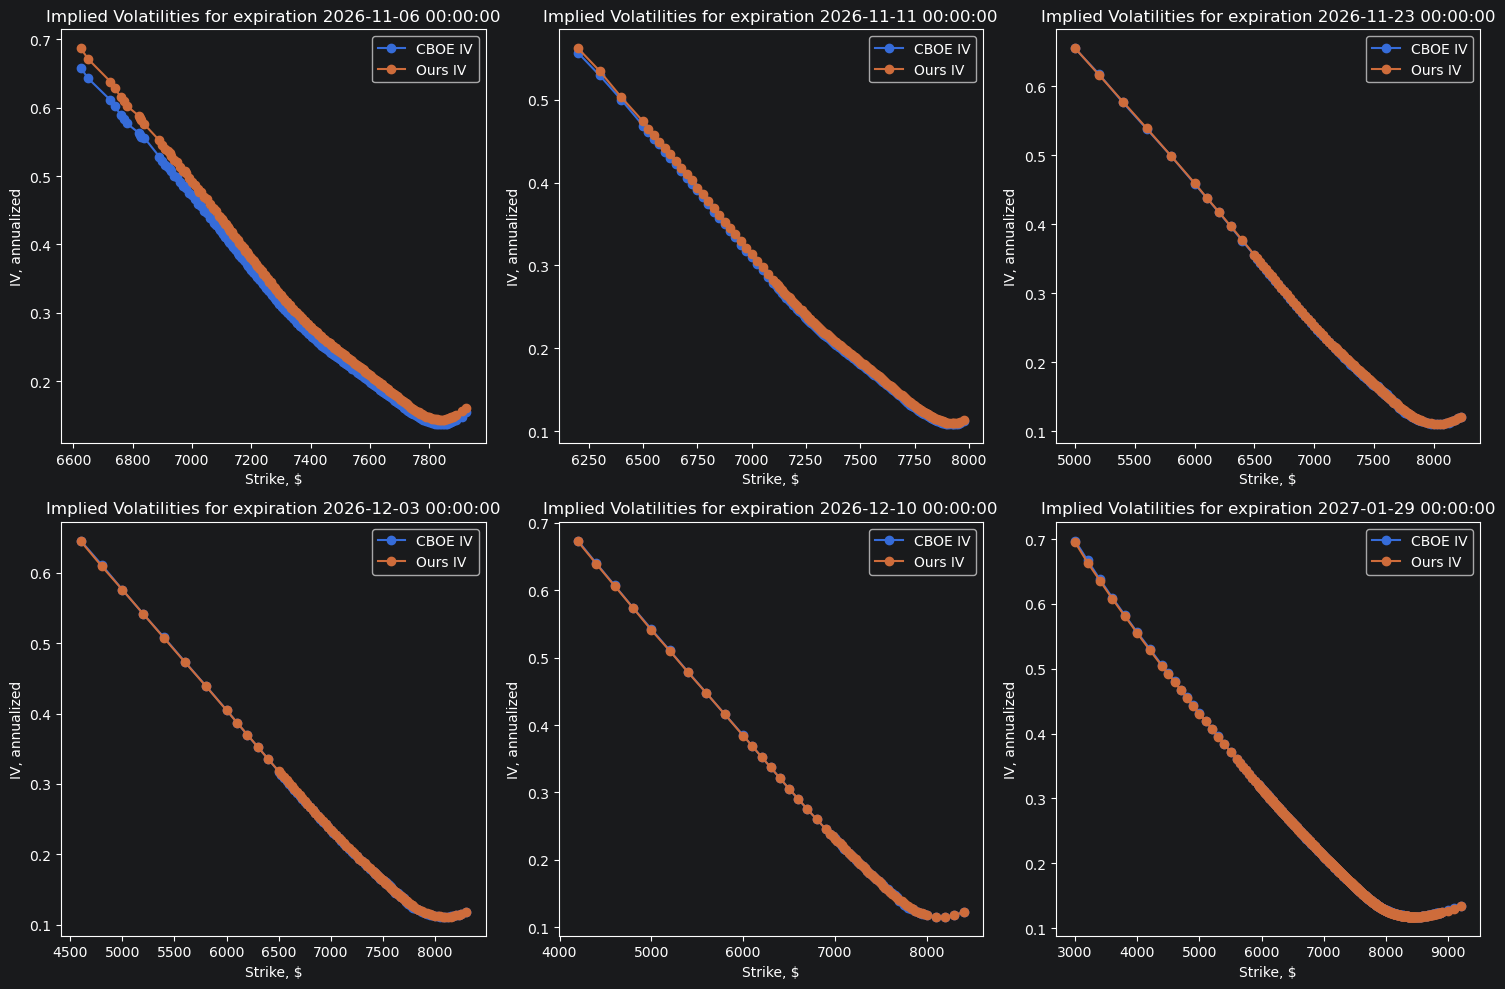

Mean squared error: 0.00002


In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

expirations = ['2026-11-06 00:00:00',
               '2026-11-11 00:00:00',
               '2026-11-23 00:00:00',
               '2026-12-03 00:00:00',
               '2026-12-10 00:00:00',
               '2027-01-29 00:00:00']

for i, ax in enumerate(axes):
    exp_mask = surface['expiration'] == expirations[i]
    ax.plot(surface[exp_mask]["strike"], surface[exp_mask]["iv"], "o-", label="CBOE IV")
    ax.plot(surface[exp_mask]["strike"], surface[exp_mask]["impl_vol"], "o-", label="Ours IV")
    ax.legend()
    ax.set_xlabel("Strike, $")
    ax.set_ylabel("IV, annualized")
    ax.set_title(f"Implied Volatilities for expiration {expirations[i]}")

plt.tight_layout()
plt.show()

print("Mean squared error: {:.5f}".format(np.mean((surface["impl_vol"] - surface["iv"])**2)))


Посмотрим на одну из улыбок волатильности, для опционов с датой экспирации 11 ноября 2026 года. График представлен в координатах log-forward-moneyness

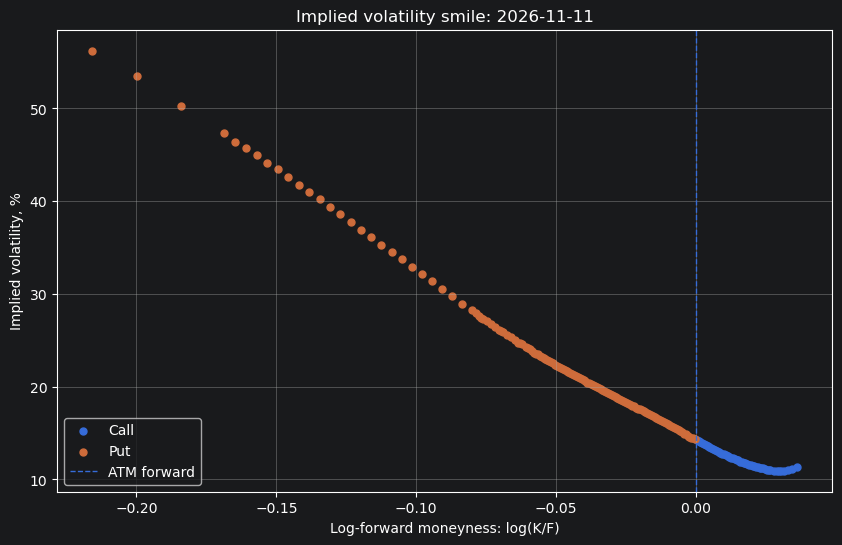

In [21]:
expiration = pd.Timestamp('2026-11-11')

smile = surface[surface['expiration'] == expiration].copy()

smile = smile.sort_values('log_moneyness')

fig, ax = plt.subplots(figsize=(10, 6))

for kind, group in smile.groupby('option_kind'):
    ax.scatter(
        group['log_moneyness'],
        group['impl_vol'] * 100,
        label=kind,
        s=25
    )

ax.axvline(
    x=0,
    linestyle='--',
    linewidth=1,
    label='ATM forward'
)

ax.set_title(f'Implied volatility smile: {expiration.date()}')
ax.set_xlabel('Log-forward moneyness: log(K/F)')
ax.set_ylabel('Implied volatility, %')

ax.legend()
ax.grid(True)

plt.show()

Изобразим полученный нами дискретный набор точек

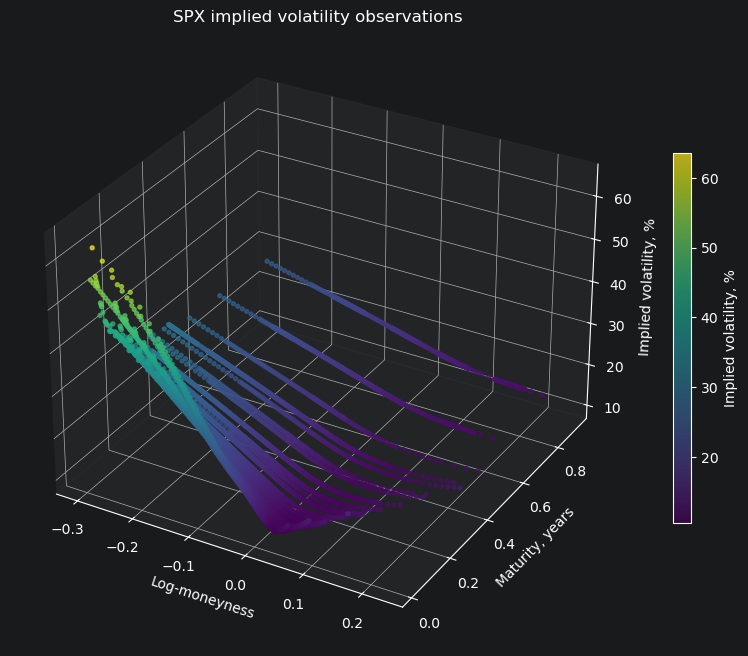

In [22]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

points = surface[
    (surface['T'] >= 7 / 365) &
    (surface['T'] <= 1) &
    (surface['log_moneyness'].abs() <= 0.3)
].copy()

scatter = ax.scatter(
    points['log_moneyness'],
    points['T'],
    points['impl_vol'] * 100,
    c=points['impl_vol'] * 100,
    s=8,
    alpha=0.7
)

ax.set_xlabel('Log-moneyness')
ax.set_ylabel('Maturity, years')
ax.set_zlabel('Implied volatility, %')
ax.set_title('SPX implied volatility observations')

fig.colorbar(
    scatter,
    ax=ax,
    shrink=0.6,
    label='Implied volatility, %'
)

plt.show()


Теперь математически опишем условия, которые необходимо соблюсти, что полученна поверхность получилась безарбитражной

Достаточное условие отсутствия статического арбитража:
1) $C(T, K)$ не убывает по $T$ (сроку до погашения) $\Leftrightarrow$ $\frac{\partial C}{\partial K} < 0$ - при нарушении данного условия существует *calendar arbitrage*
2) $C(T, K)$ выпукла по $K$ (страйку) $\Leftrightarrow$ $\frac{\partial^2 C}{\partial K^2} > 0$ - при нарушении данного условия существует *butterfly arbitrage*
3) $C(T, K) \to 0$ при $K \to \infty$;
4) $C(T, 0) = F_0$ (при нулевом страйке колл равен форварду);
5) $C(0, K) = (F_0 - K)^+$ (в момент экспирации цена равна выплате).

Теперь перепишем условия отсутствия статического арбитража в введённых обозначениях

Формула Блека:
$$
V(F_t, K, \sigma, T, B(t, T), \theta) = B(t, T) \cdot \theta \cdot \left(F_t \cdot \Phi (\frac{-\theta}{\sigma \sqrt{T}}\left(\ln \frac{K}{F_t} - \frac{\sigma^2}{2}T \right) - K \cdot \Phi (\frac{-\theta}{\sigma \sqrt{T}}\left(\ln \frac{K}{F_t} + \frac{\sigma^2}{2}T \right) \right)
$$

Введем $$z := \ln{(K/F)} \text{ is the log-moneyness. }$$

Тогда формула станет:
$$
V(F_t, K, \sigma, T, B(t, T), \theta) = B(t, T) \cdot \theta \cdot F \cdot [\Phi(- \theta \cdot (\tfrac{z}{\sigma \sqrt{T}} - \tfrac{\sigma \sqrt{T}}{2})) - e^{z} \cdot \Phi(- \theta \cdot (\tfrac{z}{\sigma \sqrt{T}} + \tfrac{\sigma \sqrt{T}}{2}))]
$$

Рассмотрим функцию

$$
v(K)
:=
V\big(F_t,K,\sigma(K),T,B(t,T),\theta\big).
$$

При фиксированном сроке до экспирации $T$ значения $F_t$, $B(t,T)$ и $T$ не зависят от страйка $K$ и поэтому являются константами при дифференцировании по $K$.

Напомним введённое обозначение

$$
z:=\ln\left(\frac{K}{F_t}\right).
$$

Тогда формула Блэка принимает вид

$$
v(K)
=
B(t,T)\,\theta F_t
\left[
\Phi\left(
-\theta
\left(
\frac{z}{\sigma(K)\sqrt{T}}
-
\frac{\sigma(K)\sqrt{T}}{2}
\right)
\right)
-
e^z
\Phi\left(
-\theta
\left(
\frac{z}{\sigma(K)\sqrt{T}}
+
\frac{\sigma(K)\sqrt{T}}{2}
\right)
\right)
\right].
$$

Введём обозначение

$$
\zeta
:=
\frac{z}{\sigma(K)\sqrt{T}}
+
\frac{\sigma(K)\sqrt{T}}{2}.
$$

Будем обозначать производные implied volatility по log-moneyness следующим образом:

$$
\sigma_z
:=
\frac{\partial\sigma}{\partial z},
\qquad
\sigma_{zz}
:=
\frac{\partial^2\sigma}{\partial z^2}.
$$

Поскольку

$$
\frac{\partial z}{\partial K}=\frac1K,
$$

имеем

$$
\frac{\partial\sigma}{\partial K}
=
\frac{\sigma_z}{K}.
$$

Первая производная цены опциона по страйку равна

$$
\boxed{
v'(K)
=
B(t,T)
\left[
\sqrt{T}\,
\phi(\zeta)\sigma_z
-
\theta\Phi(-\theta\zeta)
\right].
}
$$

Для call-опциона $\theta=1$, поэтому

$$
v'(K)
=
B(t,T)
\left[
\sqrt{T}\,
\phi(\zeta)\sigma_z
-
\Phi(-\zeta)
\right].
$$

Для отсутствия арбитража цена call-опциона должна не возрастать по страйку:

$$
v'(K)\leq0.
$$

Так как $B(t,T)>0$, это условие можно переписать в виде

$$
\boxed{
\sqrt{T}\,
\phi(\zeta)\sigma_z
-
\Phi(-\zeta)
\leq0.
}
$$

Вторая производная цены опциона по страйку имеет вид

$$
\boxed{
v''(K)
=
\frac{
B(t,T)\phi(\zeta)
}{
K\sigma(K)\sqrt{T}
}
\left[
\left(
1-\frac{z\sigma_z}{\sigma}
\right)^2
+
T\sigma\sigma_{zz}
-
\frac{T^2\sigma^2\sigma_z^2}{4}
\right].
}
$$

В соответствии с формулой Breeden–Litzenberger

$$
v''(K)
=
B(t,T)f_T(K),
$$

где $f_T(K)$ — риск-нейтральная плотность цены базового актива в момент экспирации $T$.

Для отсутствия butterfly-arbitrage необходимо потребовать

$$
v''(K)\geq0.
$$

Поскольку

$$
B(t,T)>0,
\qquad
\phi(\zeta)>0,
\qquad
K>0,
\qquad
\sigma(K)>0,
\qquad
T>0,
$$

знак второй производной определяется выражением в квадратных скобках. Следовательно, условие отсутствия butterfly-arbitrage принимает вид

$$
\boxed{
\left(
1-\frac{z\sigma_z}{\sigma}
\right)^2
+
T\sigma\sigma_{zz}
-
\frac{T^2\sigma^2\sigma_z^2}{4}
\geq0.
}
$$

Таким образом, для каждого фиксированного срока $T$ интерполяция implied volatility должна удовлетворять условиям

$$
\boxed{
\sqrt{T}\,
\phi(\zeta)\sigma_z
-
\Phi(-\zeta)
\leq0
}
$$

и

$$
\boxed{
\left(
1-\frac{z\sigma_z}{\sigma}
\right)^2
+
T\sigma\sigma_{zz}
-
\frac{T^2\sigma^2\sigma_z^2}{4}
\geq0.
}
$$

Первое условие обеспечивает невозрастание цены call-опциона по страйку, а второе — её выпуклость по страйку и отсутствие butterfly-arbitrage.

### Условие отсутствия calendar-arbitrage ###

Для анализа calendar-arbitrage необходимо учитывать зависимость от срока всех величин:

$$
B=B(t,T),
\qquad
F=F_t(T),
\qquad
\sigma=\sigma(K,T).
$$

Поэтому при сохранении общего коэффициента дисконтирования условие нельзя свести только к знаку $\sigma_T$.

Обозначим

$$
d_1
=
-\frac{z}{\sigma\sqrt{T}}
+
\frac{\sigma\sqrt{T}}{2}.
$$

Тогда производная рыночной цены по сроку при фиксированном страйке равна

$$
\frac{\partial V}{\partial T}
=
\frac{B_T(t,T)}{B(t,T)}V
+
B(t,T)
\left[
\theta\Phi(\theta d_1)F_T
+
F_t\phi(d_1)
\left(
\sqrt{T}\,\sigma_T
+
\frac{\sigma}{2\sqrt{T}}
\right)
\right],
$$

где

$$
B_T(t,T):=\frac{\partial B(t,T)}{\partial T},
\qquad
F_T:=\frac{\partial F_t(T)}{\partial T},
\qquad
\sigma_T:=\frac{\partial\sigma(K,T)}{\partial T}.
$$

При работе непосредственно с рыночными ценами условие календарной согласованности необходимо проверять с учётом данной производной.

Удобнее перейти

Попробуем проинтерполировать данные с помощью 2 ух видов сплайнов

### Кубический сплайн ###
*Кубический сплайн* интерполирует точки $(x_i, f_i)$ с помощью кубического полинома на каждом интервале $[x_i, x_{i+1}]$,
$$s(x) = a + bx + cx^2 + dx^3$$

### Рациональный кубический сплайн Дельборго–Грегори ###

*Рациональный кубический сплайн* интерполирует точки $(x_i, f_i)$ на каждом интервале $[x_i, x_{i+1}]$ рациональной функцией, задаваемой значениями $\{f_i, f_{i+1}\}$ и наклонами $\{d_i, d_{i+1}\}$:
$$s(x) = \frac{P_i(\theta)}{Q_i(\theta)}, \qquad \theta = \frac{x - x_i}{x_{i+1} - x_i},$$
$$P_i(\theta) = f_{i+1}\theta^3 + (r_i f_{i+1} - h_i d_{i+1})\theta^2(1-\theta) + (r_i f_i + h_i d_i)\theta(1-\theta)^2 + f_i(1-\theta)^3,$$
$$Q_i(\theta) = 1 + (r_i - 3)\theta(1-\theta),$$
где $h_i = x_{i+1} - x_i$, а $r_i > -1$ — *параметр кубики*.

**Выбор $r_i$.** При условии знакопостоянной монотонности
$$0 \leq \pm d_1 < \pm \Delta_1 < \pm d_2 < \dots < \pm d_i < \pm \Delta_i < \dots < \pm d_n, \qquad \Delta_i = \frac{f_{i+1} - f_i}{x_{i+1} - x_i},$$
сплайн выпукл и монотонен, если
$$r_i \geq \max\left\{\frac{d_{i+1} - d_i}{d_{i+1} - \Delta_i},\ \frac{d_{i+1} - d_i}{\Delta_i - d_i}\right\}.$$

**Аппроксимация наклонов $d_i$** (геометрическое среднее, порядок $O(h^2)$):
$$d_i = \pm(\pm\Delta_{i-1})^{(x_{i+1} - x_i)/(x_{i+1} - x_{i-1})}(\pm\Delta_i)^{(x_i - x_{i-1})/(x_{i+1} - x_{i-1})}, \quad i = 2, \dots, n-1,$$
с концевыми условиями
$$d_1 = \pm(\pm\Delta_1)^{(x_3 - x_1)/(x_3 - x_2)}(\pm\Delta_{3,1})^{-(x_2 - x_1)/(x_3 - x_2)}, \qquad d_n = \pm(\pm\Delta_{n-1})^{(x_n - x_{n-2})/(x_{n-1} - x_{n-2})}(\pm\Delta_{n,n-2})^{-(x_n - x_{n-1})/(x_{n-1} - x_{n-2})},$$
$$\Delta_{3,1} = \frac{f_3 - f_1}{x_3 - x_1}, \qquad \Delta_{n,n-2} = \frac{f_n - f_{n-2}}{x_n - x_{n-2}},$$
где знак $\pm1$ соответствует направлению монотонности данных ($+1$ — возрастание, $-1$ — убывание).